# Cat, Dog, or Neither — Complete Training Notebook

**Tech4Youth AI Engineering Capstone**

This notebook trains a three-class image classifier for `cat`, `dog`, and `neither`, evaluates it on held-out data, saves the trained model, and provides a folder-prediction function.

## Important notes before running

- Run the notebook from top to bottom in Google Colab.
- Select a GPU runtime if available: **Runtime → Change runtime type → T4 GPU** (or another available GPU).
- The notebook uses Oxford-IIIT Pet for cats/dogs and Caltech-101 for negative examples.
- Caltech-101 contains animal categories. The notebook excludes a documented list of animal-related categories and prints the categories excluded and retained. **Review that printed list before training.** If you identify another animal category, add it to the exclusion set and rerun the data-preparation cells.
- You can optionally add your own everyday `neither` photographs from Google Drive. This is strongly recommended by the brief because Caltech-101 images may not represent ordinary Nigerian surroundings.
- This notebook trains a new three-class model. It does not continue training an earlier binary model or reuse its weights.
- Confidence is the model's highest softmax probability. It is not a guarantee that the prediction is correct or a calibrated probability of real-world accuracy.


## 1. Install and import dependencies

TensorFlow and TensorFlow Datasets are used for data loading and training. Scikit-learn is used for data splitting and evaluation.

In [1]:
%pip -q install tensorflow-datasets scikit-learn pandas matplotlib pillow

In [2]:
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError

import tensorflow as tf
import tensorflow_datasets as tfds

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python / TensorFlow setup")
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

Python / TensorFlow setup
TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Project configuration

The class order is fixed throughout the notebook:

- `0 = cat`
- `1 = dog`
- `2 = neither`

The model receives RGB images resized to 224 × 224 pixels.

In [3]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 12
NUM_CLASSES = 3

CLASS_NAMES = ["cat", "dog", "neither"]

# Optional: set this to a folder in Google Drive containing only
# your own negative (neither) photographs. Leave as an empty string
# if you are not adding your own images yet.
OWN_NEITHER_DIR = ""

# Where the final model and evaluation artifacts will be saved.
OUTPUT_DIR = "/content/cat_dog_neither_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Image size:", IMAGE_SIZE)
print("Classes:", CLASS_NAMES)
print("Output directory:", OUTPUT_DIR)

Image size: (224, 224)
Classes: ['cat', 'dog', 'neither']
Output directory: /content/cat_dog_neither_output


In [4]:
%pip -q install importlib_resources

In [5]:
!rm -rf /root/tensorflow_datasets/oxford_iiit_pet

## 3. Load Oxford-IIIT Pet

The official training split (3,680 images) is divided into training and validation subsets. The official test split (3,669 images) is kept for final cat/dog testing.

The species labels are used, not the 37 breed labels.

In [6]:
oxford_train_raw, oxford_info = tfds.load(
    "oxford_iiit_pet",
    split="train",
    with_info=True,
    as_supervised=False,
    shuffle_files=True
)

oxford_test_raw = tfds.load(
    "oxford_iiit_pet",
    split="test",
    as_supervised=False,
    shuffle_files=False
)

print("Oxford dataset:", oxford_info.name)
print("Official train examples:", oxford_info.splits["train"].num_examples)
print("Official test examples:", oxford_info.splits["test"].num_examples)
print("Species label names:", oxford_info.features["species"].names)
print("Breed label count:", len(oxford_info.features["label"].names))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.HBRPOI_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.HBRPOI_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Oxford dataset: oxford_iiit_pet
Official train examples: 3680
Official test examples: 3669
Species label names: ['Cat', 'Dog']
Breed label count: 37


## 4. Load Caltech-101 and inspect its categories

**Do not skip this inspection.** The capstone brief specifically warns that Caltech-101 contains animal categories, including dog/cat-related categories. Those images must not be included as `neither`.

The exclusion set below is a starting list of animal-related category names. The next cell prints the actual dataset categories and which categories will be excluded. Review the full output and update the exclusion set if necessary.

In [7]:
caltech_raw, caltech_info = tfds.load(
    "caltech101",
    split="train",
    with_info=True,
    as_supervised=False,
    shuffle_files=True
)

caltech_class_names = caltech_info.features["label"].names

print("Caltech-101 examples:", caltech_info.splits["train"].num_examples)
print("Number of category names:", len(caltech_class_names))
print("\\nALL CALTECH-101 CATEGORIES:")
for i, name in enumerate(caltech_class_names):
    print(f"{i:3d}: {name}")

Caltech-101 examples: 3060
Number of category names: 102
\nALL CALTECH-101 CATEGORIES:
  0: accordion
  1: airplanes
  2: anchor
  3: ant
  4: background_google
  5: barrel
  6: bass
  7: beaver
  8: binocular
  9: bonsai
 10: brain
 11: brontosaurus
 12: buddha
 13: butterfly
 14: camera
 15: cannon
 16: car_side
 17: ceiling_fan
 18: cellphone
 19: chair
 20: chandelier
 21: cougar_body
 22: cougar_face
 23: crab
 24: crayfish
 25: crocodile
 26: crocodile_head
 27: cup
 28: dalmatian
 29: dollar_bill
 30: dolphin
 31: dragonfly
 32: electric_guitar
 33: elephant
 34: emu
 35: euphonium
 36: ewer
 37: faces
 38: faces_easy
 39: ferry
 40: flamingo
 41: flamingo_head
 42: garfield
 43: gerenuk
 44: gramophone
 45: grand_piano
 46: hawksbill
 47: headphone
 48: hedgehog
 49: helicopter
 50: ibis
 51: inline_skate
 52: joshua_tree
 53: kangaroo
 54: ketch
 55: lamp
 56: laptop
 57: leopards
 58: llama
 59: lobster
 60: lotus
 61: mandolin
 62: mayfly
 63: menorah
 64: metronome
 65: min

In [8]:
# Animal-related classes to exclude from the Caltech-101 negative set.
# This list must be reviewed against the category list printed above.
EXCLUDED_CALTECH_CLASSES = {
    "ant", "bass", "beaver", "brontosaurus", "butterfly",
    "cougar_body", "cougar_face", "crab", "crayfish",
    "crocodile", "crocodile_head", "dalmatian", "dolphin",
    "dragonfly", "elephant", "emu", "flamingo",
    "flamingo_head", "garfield", "gerenuk", "hawksbill",
    "hedgehog", "ibis", "kangaroo", "leopard", "leopards",
    "llama", "lobster", "mayfly", "nautilus", "octopus",
    "okapi", "panda", "platypus", "rhino", "rooster",
    "scorpion", "sea_horse", "snoopy", "starfish",
    "stegosaurus", "tick", "wild_cat"
}

def normalize_class_name(name):
    return name.strip().lower().replace(" ", "_").replace("-", "_")

excluded_found = [
    name for name in caltech_class_names
    if normalize_class_name(name) in EXCLUDED_CALTECH_CLASSES
]
retained_names = [
    name for name in caltech_class_names
    if normalize_class_name(name) not in EXCLUDED_CALTECH_CLASSES
]

print("Categories excluded as animal-related:")
print(excluded_found)
print("\\nCategories retained as candidate neither classes:")
print(retained_names)
print("\\nExcluded category count:", len(excluded_found))
print("Retained category count:", len(retained_names))

if not excluded_found:
    raise ValueError(
        "No excluded category names matched. Check the Caltech label names "
        "and update EXCLUDED_CALTECH_CLASSES before continuing."
    )
if len(retained_names) == 0:
    raise ValueError("No Caltech categories remain after exclusion.")

Categories excluded as animal-related:
['ant', 'bass', 'beaver', 'brontosaurus', 'butterfly', 'cougar_body', 'cougar_face', 'crab', 'crayfish', 'crocodile', 'crocodile_head', 'dalmatian', 'dolphin', 'dragonfly', 'elephant', 'emu', 'flamingo', 'flamingo_head', 'garfield', 'gerenuk', 'hawksbill', 'hedgehog', 'ibis', 'kangaroo', 'leopards', 'llama', 'lobster', 'mayfly', 'nautilus', 'octopus', 'okapi', 'panda', 'platypus', 'rhino', 'rooster', 'scorpion', 'sea_horse', 'snoopy', 'starfish', 'stegosaurus', 'tick', 'wild_cat']
\nCategories retained as candidate neither classes:
['accordion', 'airplanes', 'anchor', 'background_google', 'barrel', 'binocular', 'bonsai', 'brain', 'buddha', 'camera', 'cannon', 'car_side', 'ceiling_fan', 'cellphone', 'chair', 'chandelier', 'cup', 'dollar_bill', 'electric_guitar', 'euphonium', 'ewer', 'faces', 'faces_easy', 'ferry', 'gramophone', 'grand_piano', 'headphone', 'helicopter', 'inline_skate', 'joshua_tree', 'ketch', 'lamp', 'laptop', 'lotus', 'mandolin', '

## 5. Create train, validation, and test datasets

For Oxford-IIIT Pet:
- 80% of the official training split is used for training.
- 20% of the official training split is used for validation.
- The official test split is reserved for final testing.

For Caltech-101:
- Animal categories are removed first.
- The remaining examples are shuffled and divided into training, validation, and test subsets.

The Caltech test subset is combined with the Oxford official test split for a three-class test set.

In [9]:
# Convert Oxford examples into (image, class_id) pairs.
# TFDS species IDs are Cat=0 and Dog=1 in this dataset.
def oxford_to_pair(example):
    return example["image"], tf.cast(example["species"], tf.int32)

oxford_train_pairs = oxford_train_raw.map(
    oxford_to_pair,
    num_parallel_calls=tf.data.AUTOTUNE
)

oxford_test_pairs = oxford_test_raw.map(
    oxford_to_pair,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Deterministic shuffle so take() and skip() form stable, non-overlapping splits.
oxford_train_shuffled = oxford_train_pairs.shuffle(
    buffer_size=oxford_info.splits["train"].num_examples,
    seed=SEED,
    reshuffle_each_iteration=False
)

oxford_total = oxford_info.splits["train"].num_examples
oxford_train_count = int(0.80 * oxford_total)

oxford_train_part = oxford_train_shuffled.take(oxford_train_count)
oxford_val_part = oxford_train_shuffled.skip(oxford_train_count)

print("Oxford training subset:", oxford_train_count)
print("Oxford validation subset:", oxford_total - oxford_train_count)

Oxford training subset: 2944
Oxford validation subset: 736


In [10]:
# Keep only Caltech classes not listed as animal-related.
retained_class_ids = [
    i for i, name in enumerate(caltech_class_names)
    if normalize_class_name(name) not in EXCLUDED_CALTECH_CLASSES
]
retained_class_ids_tensor = tf.constant(retained_class_ids, dtype=tf.int64)

caltech_filtered = caltech_raw.filter(
    lambda example: tf.reduce_any(
        tf.equal(example["label"], retained_class_ids_tensor)
    )
)

# Every retained Caltech image is assigned class 2 = neither.
def caltech_to_neither(example):
    return example["image"], tf.constant(2, dtype=tf.int32)

caltech_pairs = caltech_filtered.map(
    caltech_to_neither,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("Counting retained Caltech examples (this may take a short while)...")
caltech_count = sum(1 for _ in caltech_pairs)
print("Retained Caltech examples:", caltech_count)

if caltech_count < 100:
    raise ValueError(
        "Too few Caltech examples remain. Recheck the exclusion list and dataset."
    )

caltech_shuffled = caltech_pairs.shuffle(
    buffer_size=caltech_count,
    seed=SEED,
    reshuffle_each_iteration=False
)

caltech_train_count = int(0.80 * caltech_count)
caltech_val_count = int(0.10 * caltech_count)

caltech_train_part = caltech_shuffled.take(caltech_train_count)
caltech_remaining = caltech_shuffled.skip(caltech_train_count)
caltech_val_part = caltech_remaining.take(caltech_val_count)
caltech_test_part = caltech_remaining.skip(caltech_val_count)

print("Caltech neither training:", caltech_train_count)
print("Caltech neither validation:", caltech_val_count)
print("Caltech neither test:", caltech_count - caltech_train_count - caltech_val_count)

Counting retained Caltech examples (this may take a short while)...
Retained Caltech examples: 1800
Caltech neither training: 1440
Caltech neither validation: 180
Caltech neither test: 180


In [11]:
def load_own_neither_image(path):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    return image, tf.constant(2, dtype=tf.int32)

own_neither_ds = None
own_image_count = 0

if OWN_NEITHER_DIR and os.path.isdir(OWN_NEITHER_DIR):
    valid_extensions = {".jpg", ".jpeg", ".png"}
    own_paths = [
        str(p) for p in Path(OWN_NEITHER_DIR).rglob("*")
        if p.is_file() and p.suffix.lower() in valid_extensions
    ]
    own_image_count = len(own_paths)

    if own_paths:
        own_neither_ds = tf.data.Dataset.from_tensor_slices(own_paths).map(
            load_own_neither_image,
            num_parallel_calls=tf.data.AUTOTUNE
        )
        print(f"Own neither images found: {own_image_count}")
    else:
        print("No JPG/JPEG/PNG images found in the selected folder.")
else:
    print("No own-image folder configured. Continuing with Caltech-101 negatives.")

if own_neither_ds is not None:
    caltech_train_part = caltech_train_part.concatenate(own_neither_ds)

No own-image folder configured. Continuing with Caltech-101 negatives.


## 7. Build the combined datasets and inspect class balance

The three labels are:
- 0: cat
- 1: dog
- 2: neither

The dataset sizes are counted before training. Class weights will be calculated to reduce the effect of class imbalance.

In [12]:
train_raw = oxford_train_part.concatenate(caltech_train_part)

train_raw = (
    oxford_train_part
    .concatenate(caltech_train_part)
    .shuffle(2000, seed=SEED, reshuffle_each_iteration=True)
)

val_raw = (
    oxford_val_part
    .concatenate(caltech_val_part)
)

test_raw = (
    oxford_test_pairs
    .concatenate(caltech_test_part)
)

def count_labels(dataset):
    counts = np.zeros(NUM_CLASSES, dtype=np.int64)
    for _, label in dataset:
        counts[int(label.numpy())] += 1
    return counts

print("Counting training labels...")
train_counts = count_labels(train_raw)
print("Counting validation labels...")
val_counts = count_labels(val_raw)
print("Counting test labels...")
test_counts = count_labels(test_raw)

balance_table = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": train_counts,
    "validation": val_counts,
    "test": test_counts
})
display(balance_table)

if np.any(train_counts == 0) or np.any(val_counts == 0) or np.any(test_counts == 0):
    raise ValueError("At least one class is missing from a split. Review dataset preparation.")

Counting training labels...
Counting validation labels...
Counting test labels...


,class,train,validation,test
0,cat,945,245,1183
1,dog,1999,491,2486
2,neither,1440,180,180


## 8. Preprocess images

Images are resized to 224 × 224. Pixel values are kept in the 0–255 range here because the model itself will contain the MobileNetV2 rescaling layer. This makes the saved model easier to use later: inference code only needs to resize the image and pass its RGB pixel array.

In [13]:
def resize_image(image, label):
    image = tf.cast(image, tf.float32)
    image = tf.image.resize(image, IMAGE_SIZE)
    label = tf.cast(label, tf.int32)
    return image, label

train_ds = (
    train_raw
    .map(resize_image, num_parallel_calls=tf.data.AUTOTUNE)
    .cache()  # Stores the small 224x224 tensors cleanly in RAM once
    .shuffle(1000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(2)  # Limit prefetch buffer so AUTOTUNE doesn't over-allocate RAM
)

val_ds = (
    val_raw
    .map(resize_image, num_parallel_calls=tf.data.AUTOTUNE)
    .cache()
    .batch(BATCH_SIZE)
    .prefetch(2)
)

test_ds = (
    test_raw
    .map(resize_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(2)
)

sample_images, sample_labels = next(iter(train_ds))
print("Image batch shape:", sample_images.shape)
print("Label batch shape:", sample_labels.shape)
print("Pixel range:", float(tf.reduce_min(sample_images)), "to", float(tf.reduce_max(sample_images)))
print("Labels in first batch:", sample_labels[:10].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 255.0
Labels in first batch: [1 1 0 1 1 1 1 1 1 1]


## 9. View sample images

Look at the training examples before training. This is an important data-quality check.

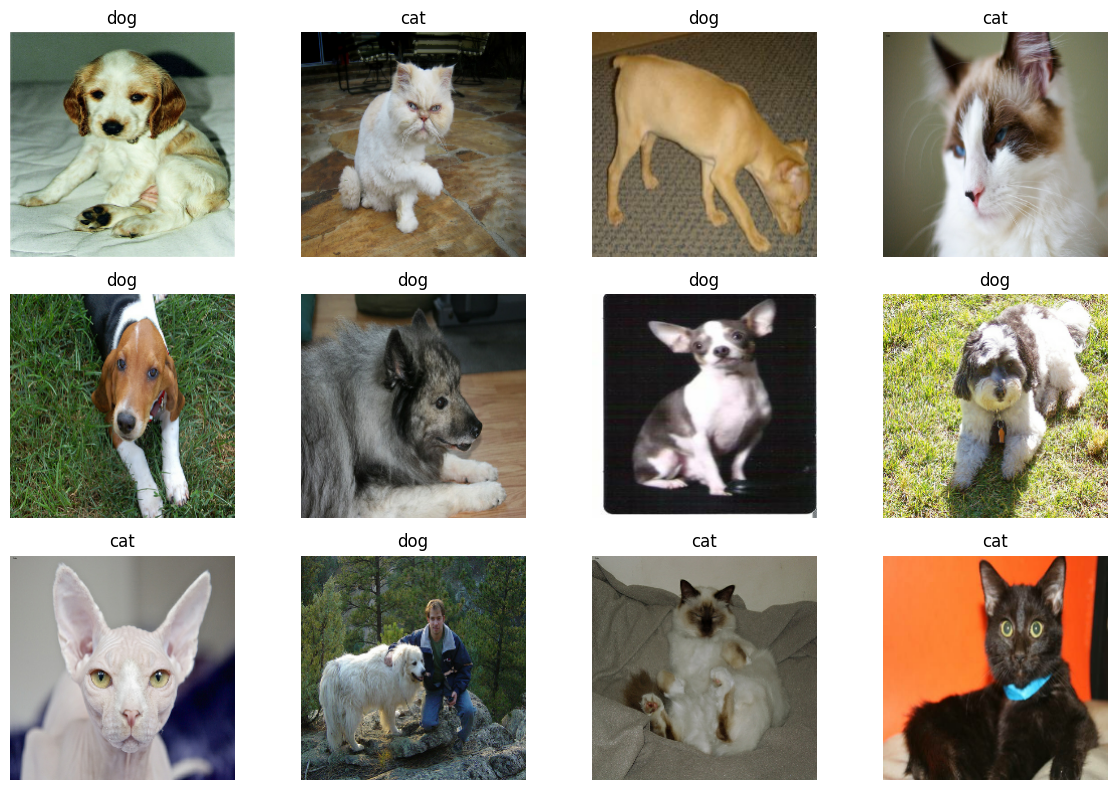

In [14]:
plt.figure(figsize=(12, 8))
for images, labels_batch in train_ds.take(1):
    n = min(12, len(images))
    for i in range(n):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8).numpy())
        plt.title(CLASS_NAMES[int(labels_batch[i].numpy())])
        plt.axis("off")
plt.tight_layout()
plt.show()

## 10. Calculate class weights

The classes may have different numbers of examples. Class weights make mistakes on a smaller class count more strongly during training.

The weights are calculated from the actual training counts printed above.

In [15]:
total_train = int(train_counts.sum())
class_weight = {
    class_id: float(total_train / (NUM_CLASSES * train_counts[class_id]))
    for class_id in range(NUM_CLASSES)
}

print("Class weights:")
for class_id, weight in class_weight.items():
    print(f"{CLASS_NAMES[class_id]}: {weight:.4f}")

Class weights:
cat: 1.5464
dog: 0.7310
neither: 1.0148


## 11. Build the three-class MobileNetV2 model

This model uses transfer learning:
- MobileNetV2 starts with ImageNet pretrained visual features.
- Its convolutional base is initially frozen.
- A small classification head learns the three project labels.
- A softmax output produces scores for `cat`, `dog`, and `neither`.

The rescaling layer is included inside the model so the saved `.keras` model contains the required pixel scaling.

In [16]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3), name="image_rgb_0_255")
x = tf.keras.layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1.0,
    name="mobilenetv2_rescaling"
)(inputs)

x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)
outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="class_probabilities"
)(x)

model = tf.keras.Model(inputs, outputs, name="cat_dog_neither")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "cat_dog_neither"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_rgb_0_255 (InputLayer)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_rescaling           │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 12. Train the model

Early stopping monitors validation loss and restores the best weights. ReduceLROnPlateau lowers the learning rate if validation loss stops improving.

Training time depends on the Colab GPU and the number of retained Caltech images.

In [17]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/12
    137/Unknown 38s 34ms/step - accuracy: 0.7892 - loss: 0.5369

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


137/137 ━━━━━━━━━━━━━━━━━━━━ 67s 250ms/step - accuracy: 0.8814 - loss: 0.3291 - val_accuracy: 0.9847 - val_loss: 0.0933 - learning_rate: 0.0010
Epoch 2/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.9852 - loss: 0.0682 - val_accuracy: 0.9869 - val_loss: 0.0613 - learning_rate: 0.0010
Epoch 3/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.9900 - loss: 0.0472 - val_accuracy: 0.9880 - val_loss: 0.0549 - learning_rate: 0.0010
Epoch 4/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.9936 - loss: 0.0341 - val_accuracy: 0.9902 - val_loss: 0.0368 - learning_rate: 0.0010
Epoch 5/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.9932 - loss: 0.0280 - val_accuracy: 0.9913 - val_loss: 0.0329 - learning_rate: 0.0010
Epoch 6/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.9970 - loss: 0.0191 - val_accuracy: 0.9913 - val_loss: 0.0290 - learning_rate: 0.0010
Epoch 7/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.9973 - loss: 0.0166 - 

## 13. Plot training history

Check whether training and validation performance move in a similar direction. A large gap can indicate overfitting.

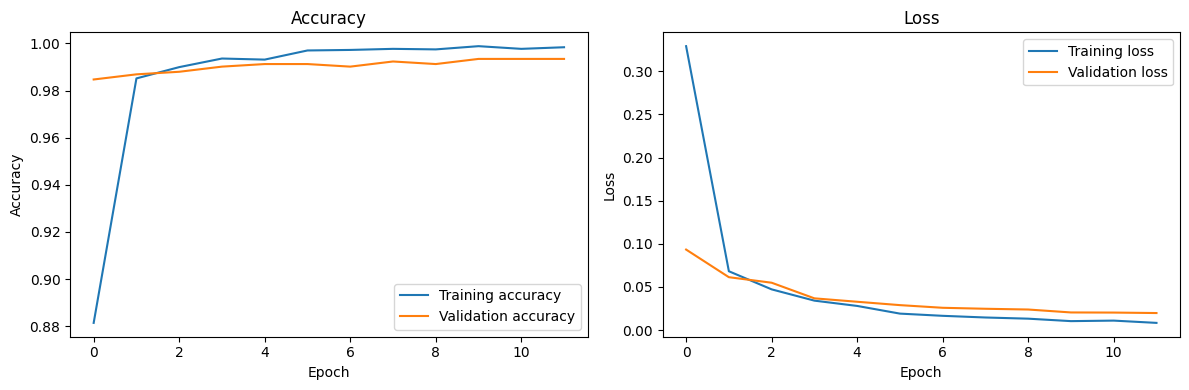

In [18]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_df["accuracy"], label="Training accuracy")
plt.plot(history_df["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history_df["loss"], label="Training loss")
plt.plot(history_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_history.png"), dpi=150)
plt.show()

## 14. Evaluate on the held-out test set

The test set combines:
- Oxford-IIIT Pet's official test split for cats and dogs.
- A held-out Caltech-101 subset for `neither`.

The test set is not used for gradient updates. Review the confusion matrix and class-level precision/recall rather than reporting accuracy alone.

121/121 ━━━━━━━━━━━━━━━━━━━━ 25s 209ms/step - accuracy: 0.9932 - loss: 0.0238
Test loss: 0.0238
Test accuracy: 0.9932
121/121 ━━━━━━━━━━━━━━━━━━━━ 18s 113ms/step
\nClassification report:
              precision    recall  f1-score   support

         cat     0.9949    0.9839    0.9894      1183
         dog     0.9944    0.9972    0.9958      2486
     neither     0.9677    1.0000    0.9836       180

    accuracy                         0.9932      3849
   macro avg     0.9857    0.9937    0.9896      3849
weighted avg     0.9933    0.9932    0.9932      3849



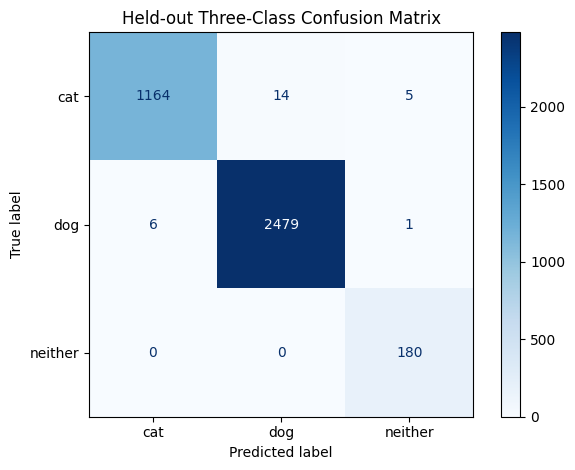

Accuracy from predictions: 0.9932449987009613


In [19]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

y_true = np.concatenate([
    labels_batch.numpy()
    for _, labels_batch in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("\\nClassification report:")
report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)
print(report)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Held-out Three-Class Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

print("Accuracy from predictions:", accuracy_score(y_true, y_pred))

## 15. Review misclassified test examples

This cell displays a selection of test images the model got wrong. Use these examples to understand failure modes and discuss limitations honestly.

Misclassified test examples: 26 out of 3849


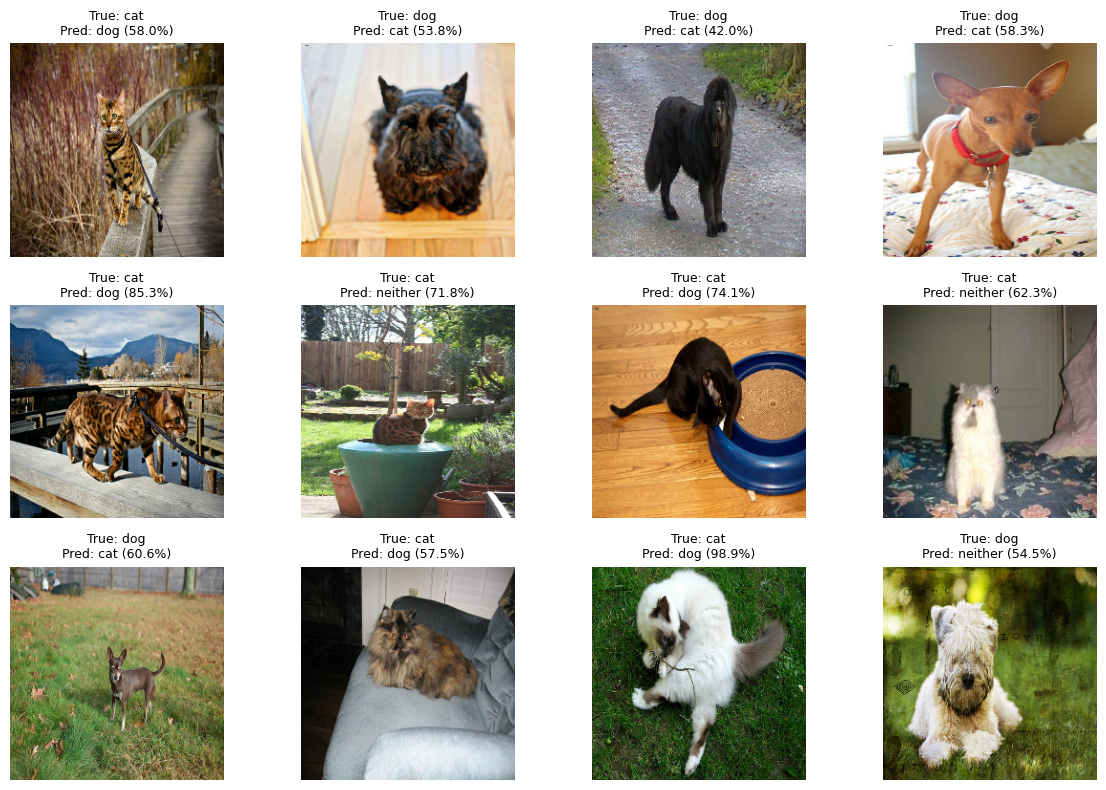

In [20]:
wrong_indices = np.where(y_true != y_pred)[0]
print("Misclassified test examples:", len(wrong_indices), "out of", len(y_true))

if len(wrong_indices) > 0:
    # Recreate a flat test image array for visual review.
    test_images = np.concatenate([
        images.numpy() for images, _ in test_ds
    ], axis=0)

    show_indices = wrong_indices[:12]
    plt.figure(figsize=(12, 8))
    for plot_i, idx in enumerate(show_indices):
        ax = plt.subplot(3, 4, plot_i + 1)
        plt.imshow(np.clip(test_images[idx], 0, 255).astype("uint8"))
        confidence = float(np.max(y_prob[idx])) * 100
        plt.title(
            f"True: {CLASS_NAMES[int(y_true[idx])] }\n"
            f"Pred: {CLASS_NAMES[int(y_pred[idx])]} ({confidence:.1f}%)",
            fontsize=9
        )
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No mistakes in this test split. Still test on external photographs.")

## 16. Save the trained model and metadata

The model includes its input rescaling layer. The class order is saved separately so the inference code can display labels consistently.

The model is saved in the required `.keras` format.

In [23]:
MODEL_PATH = os.path.join(OUTPUT_DIR, "cat_dog_neither_model.keras")
model.save(MODEL_PATH)
print("Saved model to:", MODEL_PATH)

# Save label mapping and evaluation metadata
metadata = {
    "class_names": CLASS_NAMES,
    "image_size": list(IMAGE_SIZE),
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "train_counts": {CLASS_NAMES[i]: int(train_counts[i]) for i in range(NUM_CLASSES)},
    "val_counts": {CLASS_NAMES[i]: int(val_counts[i]) for i in range(NUM_CLASSES)},
    "test_counts": {CLASS_NAMES[i]: int(test_counts[i]) for i in range(NUM_CLASSES)},
    "excluded_caltech_classes": sorted(list(EXCLUDED_CALTECH_CLASSES))
}

metadata_path = os.path.join(OUTPUT_DIR, "metadata.json")
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)
print("Saved metadata to:", metadata_path)

report_path = os.path.join(OUTPUT_DIR, "classification_report.txt")
with open(report_path, "w") as f:
    f.write(report)
print("Saved classification report to:", report_path)

Saved model to: /content/cat_dog_neither_output/cat_dog_neither_model.keras
Saved metadata to: /content/cat_dog_neither_output/metadata.json
Saved classification report to: /content/cat_dog_neither_output/classification_report.txt


## 17. Verify that the saved model reloads

This is a required capstone check. Reload the saved file and compare its predictions with the current in-memory model.

In [24]:
reloaded_model = tf.keras.models.load_model(MODEL_PATH)

# Compare predictions on one test batch.
sample_batch, _ = next(iter(test_ds))
original_output = model.predict(sample_batch, verbose=0)
reloaded_output = reloaded_model.predict(sample_batch, verbose=0)

max_difference = float(np.max(np.abs(original_output - reloaded_output)))
print("Maximum prediction difference after reload:", max_difference)
print("Reloaded model output shape:", reloaded_output.shape)

assert max_difference < 1e-5, "Reloaded model predictions differ unexpectedly."
print("Reload verification passed.")

Maximum prediction difference after reload: 0.0
Reloaded model output shape: (32, 3)
Reload verification passed.


## 18. Predict one image

This helper accepts a file path, opens the image as RGB, resizes it, and passes raw 0–255 pixel values to the model. The model's internal rescaling layer performs the MobileNetV2 scaling.

The displayed confidence is the highest softmax score. It should not be described as a guarantee of correctness.

In [25]:
def predict_image(image_path, trained_model=reloaded_model):
    image_path = str(image_path)

    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img = img.resize(IMAGE_SIZE)
        image_array = np.asarray(img, dtype=np.float32)

    batch = np.expand_dims(image_array, axis=0)
    probabilities = trained_model.predict(batch, verbose=0)[0]

    predicted_id = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_id])

    return {
        "filename": os.path.basename(image_path),
        "prediction": CLASS_NAMES[predicted_id],
        "confidence": confidence,
        "class_scores": {
            CLASS_NAMES[i]: float(probabilities[i])
            for i in range(NUM_CLASSES)
        }
    }

print("Prediction helper is ready.")
print("Example use: predict_image('/content/example.jpg')")

Prediction helper is ready.
Example use: predict_image('/content/example.jpg')


## 19. Predict every image in a folder

Change `IMAGE_FOLDER` to the folder containing the images. The function supports JPG, JPEG, and PNG files, handles different image dimensions by resizing, and reports unreadable files instead of stopping the whole batch.

In [26]:
def predict_folder(folder_path, trained_model=reloaded_model):
    folder = Path(folder_path)
    if not folder.exists() or not folder.is_dir():
        raise ValueError(f"Folder does not exist: {folder_path}")

    supported = {".jpg", ".jpeg", ".png"}
    image_paths = sorted([
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in supported
    ])

    rows = []
    errors = []

    for path in image_paths:
        try:
            result = predict_image(path, trained_model)
            rows.append({
                "filename": result["filename"],
                "prediction": result["prediction"],
                "confidence": f"{result['confidence'] * 100:.2f}%"
            })
        except (UnidentifiedImageError, OSError, ValueError) as exc:
            errors.append({
                "filename": path.name,
                "error": str(exc)
            })

    results_df = pd.DataFrame(
        rows,
        columns=["filename", "prediction", "confidence"]
    )

    if errors:
        print("Files that could not be processed:")
        display(pd.DataFrame(errors))

    return results_df

# Change this to your own folder path.
IMAGE_FOLDER = "/content/test_images"

if os.path.isdir(IMAGE_FOLDER):
    folder_results = predict_folder(IMAGE_FOLDER)
    display(folder_results)
else:
    print(f"Create or upload an image folder at {IMAGE_FOLDER}, then rerun this cell.")
    print("Example: IMAGE_FOLDER = '/content/drive/MyDrive/capstone_test_images'")

Create or upload an image folder at /content/test_images, then rerun this cell.
Example: IMAGE_FOLDER = '/content/drive/MyDrive/capstone_test_images'


## 20. Download the model and project artifacts

Download the `.keras` model, label mapping, metrics, confusion matrix, and training plot from Colab. Keep the notebook, model, and a short README in your class repository.

For a fresh-runtime test, restart the runtime, load the saved `.keras` file, and run inference without executing the training cells.

In [27]:
# Create a ZIP containing the main deliverables.
import shutil

ZIP_PATH = shutil.make_archive(
    "/content/cat_dog_neither_artifacts",
    "zip",
    OUTPUT_DIR
)

print("Artifact ZIP:", ZIP_PATH)
print("Contents:")
for p in sorted(Path(OUTPUT_DIR).iterdir()):
    print("-", p.name, f"({p.stat().st_size / (1024 * 1024):.2f} MB)")

from google.colab import files
files.download(ZIP_PATH)

Artifact ZIP: /content/cat_dog_neither_artifacts.zip
Contents:
- cat_dog_neither_model.keras (9.22 MB)
- classification_report.txt (0.00 MB)
- confusion_matrix.png (0.04 MB)
- metadata.json (0.00 MB)
- training_history.png (0.07 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 21. Final checklist and interpretation

Before treating the capstone as complete, verify all of the following:

- [ ] Review the full Caltech-101 category list and document excluded animal classes.
- [ ] Record actual training, validation, and test counts for each class.
- [ ] Record the real classification report and confusion matrix.
- [ ] Test on at least 20 photographs from outside the training datasets, preferably ordinary Nigerian surroundings.
- [ ] Inspect mistakes and record why they may have occurred.
- [ ] Test the saved model in a fresh Colab runtime without retraining.
- [ ] Test the folder prediction function with different image sizes and JPG/JPEG/PNG files.
- [ ] Keep the notebook, `.keras` model, and short README in the class repository.
- [ ] Prepare to explain the model, the `neither` data choice, the confusion matrix, precision, recall, and limitations.

### Important limitation

Caltech-101 images are not a complete representation of everything that is neither a cat nor a dog. A three-class classifier can still confidently misclassify unfamiliar animals, unusual objects, poor-quality photos, or scenes that differ from its training data. The external-photo test is essential. Do not report the softmax score as a calibrated probability that the answer is correct.

### Suggested README contents

1. Project objective.
2. Datasets used and animal categories excluded from Caltech-101.
3. Model architecture and preprocessing.
4. Actual class counts and evaluation results.
5. How to load the model and run folder inference.
6. Known limitations and failure examples.
